# 1. Project Introduction

**A Feature Selection and Support Vector Machine-Based Framework for High-Accuracy Breast Cancer Diagnosis.**

This notebook will provide the workspace for the project. The complete model is not implemented yet.

# 2. Importing Required Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import sklearn
from ucimlrepo import fetch_ucirepo
import joblib


# 3. Loading the Dataset

Load the Wisconsin Diagnostic Breast Cancer dataset from the UCI Machine Learning Repository (dataset ID 17). It contains 569 observations and 30 features. The feature table is stored in `X`, and the diagnosis labels are stored in `y`. See the [official UCI dataset page](https://archive.ics.uci.edu/dataset/17/breast+cancer).

In [2]:
breast_cancer_data = fetch_ucirepo(id=17)
X = breast_cancer_data.data.features.copy()
y = breast_cancer_data.data.targets.squeeze("columns").copy()

print(f"Dataset shape: {X.shape[0]} observations, {X.shape[1]} features")
print("Diagnosis label counts:")
print(y.value_counts())

display(X.head())
display(y.head())


Dataset shape: 569 observations, 30 features
Diagnosis label counts:
Diagnosis
B    357
M    212
Name: count, dtype: int64


,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,fractal_dimension1,...,radius3,texture3,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


0    M
1    M
2    M
3    M
4    M
Name: Diagnosis, dtype: str

# 4. Understanding the Dataset

In [3]:
print("Feature data types:")
print(X.dtypes.value_counts())

print("Missing feature values:", X.isna().sum().sum())
print("Duplicate feature rows:", X.duplicated().sum())

display(X.describe().T)


Feature data types:
float64    30
Name: count, dtype: int64
Missing feature values: 0
Duplicate feature rows: 0


,count,mean,std,min,25%,50%,75%,max
radius1,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
texture1,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
perimeter1,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
area1,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
smoothness1,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
compactness1,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
concavity1,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
concave_points1,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
symmetry1,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
fractal_dimension1,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


# 5. Data Preprocessing

In [4]:
y_encoded = y.map({"B": 0, "M": 1}).astype("int64")
print(y_encoded.value_counts().sort_index())


Diagnosis
0    357
1    212
Name: count, dtype: int64


# 6. Exploratory Data Analysis

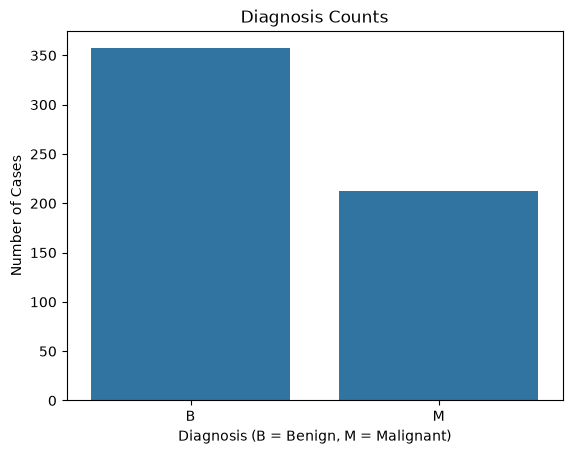

In [5]:
sns.countplot(x=y, order=["B", "M"])
plt.title("Diagnosis Counts")
plt.xlabel("Diagnosis (B = Benign, M = Malignant)")
plt.ylabel("Number of Cases")
plt.show()


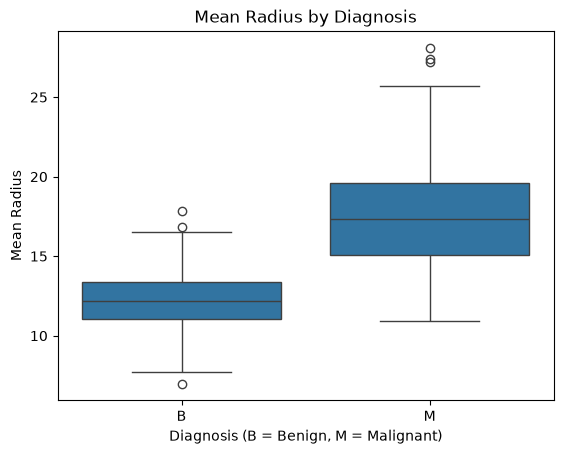

In [6]:
sns.boxplot(x=y, y=X["radius1"], order=["B", "M"])
plt.title("Mean Radius by Diagnosis")
plt.xlabel("Diagnosis (B = Benign, M = Malignant)")
plt.ylabel("Mean Radius")
plt.show()


# 7. Feature Selection

In [7]:
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC


def make_svm_pipeline(n_features, k=10, C=1.0, kernel="rbf"):
    """Create a reusable scaling, feature-selection, and SVM pipeline."""
    if n_features < 1 or k < 1:
        raise ValueError("n_features and k must be positive integers")
    k = min(k, n_features)

    return Pipeline([
        ("scaler", StandardScaler()),
        ("feature_selection", SelectKBest(score_func=f_classif, k=k)),
        ("svm", SVC(C=C, kernel=kernel)),
    ])


# 8. Support Vector Machine

A Support Vector Machine (SVM) is a supervised learning method that separates classes by finding a decision boundary with the widest possible margin. The closest training points are called support vectors.

This project uses the radial basis function (RBF) kernel, which can model nonlinear boundaries. The pipeline scales features before fitting the SVM because the measurements use different ranges. The parameter C controls the trade-off between a wider margin and penalizing training errors.

# 9. Model Training

In [10]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

svm_pipeline = make_svm_pipeline(
    n_features=X_train.shape[1],
    k=10
)

svm_pipeline.fit(X_train, y_train)

print("Training samples:", len(X_train))
print("Test samples:", len(X_test))

Training samples: 455
Test samples: 114


In [14]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

parameter_grid = [
    {
        "feature_selection__k": [5, 10, 20, 30],
        "svm__C": [0.1, 1, 10],
        "svm__kernel": ["linear"],
        "svm__class_weight": [None, "balanced"],
    },
    {
        "feature_selection__k": [5, 10, 20, 30],
        "svm__C": [0.1, 1, 10],
        "svm__kernel": ["rbf"],
        "svm__gamma": ["scale", "auto"],
        "svm__class_weight": [None, "balanced"],
    },
]

grid_search = GridSearchCV(
    estimator=make_svm_pipeline(n_features=X_train.shape[1]),
    param_grid=parameter_grid,
    scoring={
        "recall": "recall",
        "precision": "precision",
        "f1": "f1",
        "accuracy": "accuracy",
    },
    refit="recall",
    cv=cv,
    n_jobs=1,
)

grid_search.fit(X_train, y_train)
svm_pipeline = grid_search.best_estimator_

best_index = grid_search.best_index_
print("Best cross-validation malignant recall:", round(grid_search.best_score_, 3))
print(
    "Cross-validation malignant precision:",
    round(grid_search.cv_results_["mean_test_precision"][best_index], 3)
)
print("Best settings:", grid_search.best_params_)

Best cross-validation malignant recall: 0.965
Cross-validation malignant precision: 0.971
Best settings: {'feature_selection__k': 30, 'svm__C': 10, 'svm__class_weight': None, 'svm__gamma': 'scale', 'svm__kernel': 'rbf'}


# 10. Model Evaluation

In [20]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)

y_pred = svm_pipeline.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Malignant precision:", round(precision_score(y_test, y_pred, pos_label=1), 4))
print("Malignant recall:", round(recall_score(y_test, y_pred, pos_label=1), 4))
print("Malignant F1-score:", round(f1_score(y_test, y_pred, pos_label=1), 4))

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Benign (0)", "Malignant (1)"]
))

print("Confusion matrix (rows = actual, columns = predicted):")
print(confusion_matrix(y_test, y_pred, labels=[0, 1]))

Accuracy: 0.9737
Malignant precision: 1.0
Malignant recall: 0.9286
Malignant F1-score: 0.963

Classification report:
               precision    recall  f1-score   support

   Benign (0)       0.96      1.00      0.98        72
Malignant (1)       1.00      0.93      0.96        42

     accuracy                           0.97       114
    macro avg       0.98      0.96      0.97       114
 weighted avg       0.97      0.97      0.97       114

Confusion matrix (rows = actual, columns = predicted):
[[72  0]
 [ 3 39]]


# 11. False Negative Analysis

In [21]:
false_negative_mask = y_test.eq(1).to_numpy() & (y_pred == 0)
false_negative_indices = y_test.index[false_negative_mask]

false_negatives = X_test.loc[false_negative_indices].copy()
false_negatives["Actual diagnosis"] = y.loc[false_negative_indices]
false_negatives["Predicted diagnosis"] = "B"

print("False negatives:", len(false_negatives))
display(false_negatives)

False negatives: 3


,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,fractal_dimension1,...,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3,Actual diagnosis,Predicted diagnosis
99,14.42,19.77,94.48,642.5,0.09752,0.11410,0.09388,0.05839,0.1879,0.06390,...,109.5,826.4,0.1431,0.3026,0.3194,0.1565,0.2718,0.09353,M,B
73,13.80,15.79,90.43,584.1,0.10070,0.12800,0.07789,0.05069,0.1662,0.06566,...,110.3,812.4,0.1411,0.3542,0.2779,0.1383,0.2589,0.10300,M,B
205,15.12,16.68,98.78,716.6,0.08876,0.09588,0.07550,0.04079,0.1594,0.05986,...,117.7,989.5,0.1491,0.3331,0.3327,0.1252,0.3415,0.09740,M,B


# 12. Results and Discussion

The tuned SVM achieved 97.4% accuracy on the test set. It correctly identified all cases it predicted as malignant (100% malignant precision) and detected 92.9% of the malignant cases. It missed 3 malignant cases, so reducing false negatives should be considered in future improvements.

In [24]:
tuned_metrics = pd.DataFrame({
    "Accuracy": [accuracy_score(y_test, y_pred)],
    "Precision (malignant)": [precision_score(y_test, y_pred, pos_label=1)],
    "Recall (malignant)": [recall_score(y_test, y_pred, pos_label=1)],
    "F1-score (malignant)": [f1_score(y_test, y_pred, pos_label=1)],
    "False negatives": [len(false_negatives)],
}, index=["Tuned SVM"])

display(tuned_metrics.round(3))

,Accuracy,Precision (malignant),Recall (malignant),F1-score (malignant),False negatives
Tuned SVM,0.974,1.0,0.929,0.963,3


# 13. Conclusion

This project developed and evaluated a feature-selection and SVM approach for classifying the Wisconsin Diagnostic Breast Cancer dataset. The tuned model achieved 97.4% accuracy and 92.9% malignant recall on the held-out test set. It missed three malignant cases, so reducing false negatives remains an important area for future improvement. These results are from this dataset and test split; further validation is needed before drawing broader conclusions.